---
# **4. TEMPERATURA DEL SUELO Y NDVI**

**Objetivo:** medir el calor del suelo y la vegetación de cada barrio a partir de imágenes de satélite.

**Entradas:**
- En **`data/raw/earthengine`**: `temperatura_barrios.csv` y `ndvi_barrios.csv` (estadísticas por barrio calculadas en QGIS a partir de imágenes obtenidas con Google Earth Engine).
- En **`data/processed`**: `barrios_base.gpkg` (cuaderno 1).

**Fuente y año:** Landsat 8 y 9, nivel L2SP, del 1 de junio al 30 de septiembre de 2026, con menos del 10 % de nubes. Valor de cada píxel: mediana de las imágenes del periodo.

**Salidas** (en `data/processed`): `temperatura_por_barrio.csv` y `ndvi_por_barrio.csv`, una fila por barrio con `codi_barri` y sus estadísticas.

**Limitaciones:**
- Es la temperatura del **suelo**, no la del aire.
- Landsat pasa sobre Barcelona a media mañana (≈10:30 hora solar), no en el máximo térmico del día.
- La banda térmica se mide a 100 m y se remuestrea a 30 m.
- Los barrios de costa mezclan píxeles de mar y tierra.

---

## Metodología previa: Obtención y Procesamiento de Datos

Antes de iniciar el análisis estadístico en este cuaderno de Python, se realizaron dos fases clave de preparación y procesamiento espacial con Earth Engine y Qgis. Para ello, se han utilizado imágenes tomadas por satélites que observan la superficie terrestre. Y a partir de estas imágenes se han obtenido dos indicadores: uno que permite estimar la presencia de vegetación y otro que mide la temperatura de la superficie.

El análisis se ha realizado para los **73 barrios oficiales de Barcelona**, de manera que podemos comparar cómo se distribuyen la vegetación y el calor por toda la ciudad.

## A. ¿De dónde proceden las imágenes?

Los datos originales de satélite se obtuvieron y preprocesaron de forma remota utilizando la API de Google Earth Engine (GEE)

En concreto, se han utilizado imágenes de dos satélites:

- **Landsat 8**
- **Landsat 9**

Estos satélites observan la Tierra desde el espacio y captan información de la superficie mediante diferentes sensores. Algunos registran la luz reflejada por la vegetación y otros permiten estimar la temperatura de los materiales y superficies urbanas.

Para este estudio se han seleccionado imágenes correspondientes al periodo comprendido entre el **1 de junio y el 30 de septiembre de 2026**, con el objetivo de analizar las condiciones de la ciudad durante los meses de verano.

## B. ¿Cómo se han seleccionado las imágenes?

No todas las imágenes satelitales sirven para realizar este análisis. La presencia de nubes puede dificultar la observación de la superficie terrestre y alterar los resultados.

Por este motivo, se han aplicado dos criterios principales:

- Se han seleccionado imágenes con una cobertura nubosa inferior al 10 % (`CLOUD_COVER < 10`).
- Se han utilizado exclusivamente imágenes de nivel de procesamiento **Level 2 Surface Temperature (L2SP)**, que contienen información corregida de reflectancia y temperatura superficial.

Además, se ha utilizado la información de calidad de los píxeles (`QA_PIXEL`) para identificar y excluir observaciones afectadas por nubes y sombras.

De este modo, se trabaja con observaciones más adecuadas para estudiar tanto la vegetación como la temperatura del suelo urbano.

## C. ¿Qué información se ha extraído de los satélites?

A partir de las imágenes seleccionadas se han calculado dos indicadores diferentes:

### NDVI: presencia de vegetación

Se calcula utilizando dos bandas del satélite: la banda roja (`SR_B4`) y la del infrarrojo cercano (`SR_B5`).

Permite estimar la presencia y el vigor de la vegetación. Sus valores suelen oscilar entre -1 y 1: cuanto más alto es el valor positivo, mayor suele ser la presencia de vegetación verde.

### Temperatura superficial: calor del suelo

Se obtiene a partir de la banda térmica `ST_B10`.

Permite estimar la temperatura de las superficies terrestres, como el asfalto, los tejados, los parques o el suelo desnudo. Los resultados se expresan en grados Celsius (°C).

Es importante destacar que esta temperatura no corresponde a la temperatura del aire que indican los termómetros meteorológicos, sino a la temperatura de la superficie observada por el satélite.

## D. ¿Cómo se han preparado los datos?

Una vez obtenidos los indicadores, se han generado dos imágenes resumen para todo el periodo de estudio: una de NDVI y otra de temperatura superficial.

En ambos casos se ha utilizado la **mediana de las observaciones disponibles**. Esto significa que, para cada píxel, se ha calculado el valor central de las mediciones válidas realizadas durante el periodo.

La mediana permite reducir la influencia de valores puntuales extremos y obtener una representación general de las condiciones observadas durante el verano de 2026.

Los dos resultados se han exportado en formato ráster GeoTIFF (`.tif`), un formato que permite almacenar información geográfica en forma de píxeles.

## E. ¿Cómo se han adaptado los datos a los 73 barrios de Barcelona?

Para poder comparar los resultados por barrios, se ha utilizado el programa **QGIS 3.44**, un software de información geográfica que permite trabajar con mapas y datos espaciales.

Primero, se ha preparado la cartografía oficial de los 73 barrios y se ha establecido un sistema de coordenadas común: **ETRS89 / UTM zona 31N (EPSG:25831)**. Esto permite que los límites de los barrios y las imágenes satelitales coincidan correctamente en el espacio.

A continuación, se ha utilizado la capa de los barrios como **capa máscara** para recortar las dos imágenes ráster.

En otras palabras, se han eliminado las zonas de las imágenes que quedan fuera de los límites de los barrios de Barcelona y se ha conservado únicamente la información correspondiente al territorio de estudio.

Así, se han obtenido dos rásteres adaptados al mismo ámbito geográfico: uno con los valores de NDVI y otro con los valores de temperatura superficial.

## F. ¿Cómo se han obtenido los valores de cada barrio?

El último paso ha consistido en calcular las estadísticas de cada barrio mediante la herramienta **«Estadística de zona» de QGIS**.

Esta herramienta permite resumir todos los valores de los píxeles que se encuentran dentro de cada polígono (en este caso, cada barrio).

Para cada uno de los 73 barrios se han calculado seis estadísticas:

| Estadística | Qué nos indica |
|---|---|
| Número de píxeles | Cuántos píxeles válidos se han utilizado |
| Media | El valor promedio del barrio |
| Mediana | El valor central del barrio |
| Desviación estándar | Cuánto varían los valores dentro del barrio |
| Mínimo | El valor más bajo registrado |
| Máximo | El valor más alto registrado |

Este procedimiento se ha realizado por separado para los dos indicadores: NDVI y temperatura superficial.

Finalmente, los resultados se han exportado en formato CSV, lo que permite organizar los datos en tablas para poder analizarlos con Python en Google Colab.



In [51]:
from google.colab import drive
drive.mount('/content/drive')

CARPETA = '/content/drive/MyDrive/proyectofinal_ITAcademy/'
RAW = CARPETA + 'data/raw/'                           # Ruta limpia a la carpeta de datos originales
PROCESSED = CARPETA + 'data/processed/'              # Ruta limpia a la carpeta de procesados

import os
os.makedirs(PROCESSED, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


 Cargamos las librerías: **pandas** trabaja con tablas, **geopandas** es pandas con mapas y **matplotlib** dibuja gráficos.

In [52]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)    # que pandas enseñe todas las columnas

### 1. Cargamos los datos

In [53]:
RUTA = RAW + 'earthengine/'

temp = pd.read_csv(RUTA + 'temperatura_barrios.csv', encoding='utf-8-sig')
ndvi = pd.read_csv(RUTA + 'ndvi_barrios.csv', encoding='utf-8-sig')

print('Temperatura:', temp.shape, '| NDVI:', ndvi.shape)

Temperatura: (73, 41) | NDVI: (73, 41)


## 2. Inspección de los datos

### 2.1 Inspección completa de variables y estructura de los DataFrames
Vamos a listar todas las columnas disponibles para entender qué datos contiene cada archivo (temperatura y NDVI).

In [54]:
# Mostrar la lista completa de todas las columnas de la tabla de temperatura
print("--- COLUMNAS EN LA TABLA DE TEMPERATURA ---")
print(temp.columns.tolist())

print("\n--- COLUMNAS EN LA TABLA DE NDVI ---")
print(ndvi.columns.tolist())

# Comparación de las columnas
mismas_columnas = set(temp.columns) == set(ndvi.columns)
print('\nLos dos archivos tienen las mismas columnas:', mismas_columnas)

--- COLUMNAS EN LA TABLA DE TEMPERATURA ---
['fid', 'ID_ANNEX', 'ANNEXDESCR', 'ID_TEMA', 'TEMA_DESCR', 'ID_CONJUNT', 'CONJ_DESCR', 'ID_SUBCONJ', 'SCONJ_DESC', 'ID_ELEMENT', 'ELEM_DESCR', 'NIVELL', 'NDESCR_CA', 'NDESCR_ES', 'NDESCR_EN', 'TERME', 'DISTRICTE', 'BARRI', 'AEB', 'SEC_CENS', 'GRANBARRI', 'ZUA', 'AREA_I', 'LITERAL', 'PERIMETRE', 'AREA', 'CODI_UA', 'TIPUS_UA', 'NOM', 'WEB1', 'WEB2', 'WEB3', 'FHEX_COLOR', 'Shape_Leng', 'Shape_Area', 'temp_count', 'temp_mean', 'temp_median', 'temp_stdev', 'temp_min', 'temp_max']

--- COLUMNAS EN LA TABLA DE NDVI ---
['fid', 'ID_ANNEX', 'ANNEXDESCR', 'ID_TEMA', 'TEMA_DESCR', 'ID_CONJUNT', 'CONJ_DESCR', 'ID_SUBCONJ', 'SCONJ_DESC', 'ID_ELEMENT', 'ELEM_DESCR', 'NIVELL', 'NDESCR_CA', 'NDESCR_ES', 'NDESCR_EN', 'TERME', 'DISTRICTE', 'BARRI', 'AEB', 'SEC_CENS', 'GRANBARRI', 'ZUA', 'AREA_I', 'LITERAL', 'PERIMETRE', 'AREA', 'CODI_UA', 'TIPUS_UA', 'NOM', 'WEB1', 'WEB2', 'WEB3', 'FHEX_COLOR', 'Shape_Leng', 'Shape_Area', 'ndvi_count', 'ndvi_mean', 'ndvi_media

In [55]:
# Encontrar y mostrar de forma directa qué columnas son diferentes entre ambos archivos
columnas_diferentes = set(temp.columns) ^ set(ndvi.columns)
print("Las columnas que cambian entre ambos archivos son precisamente las estadísticas del final:")
print(sorted(list(columnas_diferentes)))

Las columnas que cambian entre ambos archivos son precisamente las estadísticas del final:
['ndvi_count', 'ndvi_max', 'ndvi_mean', 'ndvi_median', 'ndvi_min', 'ndvi_stdev', 'temp_count', 'temp_max', 'temp_mean', 'temp_median', 'temp_min', 'temp_stdev']


In [56]:
# Resumen del tipo de datos e información general
print("--- INFORMACIÓN GENERAL DE TEMPERATURA ---")
temp.info()

--- INFORMACIÓN GENERAL DE TEMPERATURA ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73 entries, 0 to 72
Data columns (total 41 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   fid          73 non-null     int64  
 1   ID_ANNEX     73 non-null     int64  
 2   ANNEXDESCR   73 non-null     object 
 3   ID_TEMA      73 non-null     int64  
 4   TEMA_DESCR   73 non-null     object 
 5   ID_CONJUNT   73 non-null     int64  
 6   CONJ_DESCR   73 non-null     object 
 7   ID_SUBCONJ   73 non-null     int64  
 8   SCONJ_DESC   73 non-null     object 
 9   ID_ELEMENT   73 non-null     int64  
 10  ELEM_DESCR   73 non-null     object 
 11  NIVELL       73 non-null     object 
 12  NDESCR_CA    73 non-null     object 
 13  NDESCR_ES    73 non-null     object 
 14  NDESCR_EN    73 non-null     object 
 15  TERME        73 non-null     int64  
 16  DISTRICTE    73 non-null     int64  
 17  BARRI        73 non-null     int64  
 18  AEB      

**Qué mirar:** las primeras columnas son información administrativa del Ayuntamiento (`ID_ANNEX`, `TEMA_DESCR`...) que no nos sirve para nada. Lo importante está al final y en dos o tres columnas sueltas.

### 2.2 ¿Qué columnas aportan información?

Una columna con **un solo valor** en todas las filas no sirve para analizar. Con `nunique()` contamos cuántos valores distintos tiene cada una.

In [57]:
n_valores = temp.nunique()
print('Columnas con un solo valor (no aportan nada):', int((n_valores == 1).sum()))
print(n_valores[n_valores == 1].index.tolist())
print()
print('Columnas con varios valores:')
print(n_valores[n_valores > 1].index.tolist())

Columnas con un solo valor (no aportan nada): 21
['ID_ANNEX', 'ANNEXDESCR', 'ID_TEMA', 'TEMA_DESCR', 'ID_CONJUNT', 'CONJ_DESCR', 'ID_SUBCONJ', 'SCONJ_DESC', 'ID_ELEMENT', 'ELEM_DESCR', 'NIVELL', 'NDESCR_CA', 'NDESCR_ES', 'NDESCR_EN', 'TERME', 'AEB', 'SEC_CENS', 'ZUA', 'AREA_I', 'TIPUS_UA', 'FHEX_COLOR']

Columnas con varios valores:
['fid', 'DISTRICTE', 'BARRI', 'GRANBARRI', 'LITERAL', 'PERIMETRE', 'AREA', 'CODI_UA', 'NOM', 'WEB1', 'WEB2', 'WEB3', 'Shape_Leng', 'Shape_Area', 'temp_count', 'temp_mean', 'temp_median', 'temp_stdev', 'temp_min', 'temp_max']


**Qué mirar:** de las que varían, las importantes son:
- `BARRI`: el **código** del barrio (del 1 al 73).
- `NOM`: el **nombre**.
- `DISTRICTE`: el distrito.
- `AREA`: la superficie del barrio en m².
- Las **estadísticas** que añadió QGIS, con prefijo `temp_` o `ndvi_`: `count` (píxeles), `mean` (media), `median` (mediana), `stdev` (desviación), `min` y `max`.

Las demás (enlaces web, colores, códigos del Ayuntamiento) las descartamos.

### 2.3 Valores vacíos y duplicados

In [58]:
for nombre, t in [('temperatura', temp), ('NDVI', ndvi)]:
    print(nombre, '-> vacíos:', int(t.isna().sum().sum()), '| códigos de barrio repetidos:', int(t['BARRI'].duplicated().sum()))

print('Los dos archivos tienen los mismos códigos de barrio y en el mismo orden:', (temp['BARRI'].values == ndvi['BARRI'].values).all())

temperatura -> vacíos: 0 | códigos de barrio repetidos: 0
NDVI -> vacíos: 0 | códigos de barrio repetidos: 0
Los dos archivos tienen los mismos códigos de barrio y en el mismo orden: True


## 3. Limpieza

### 3.1 Nos quedamos solo con lo que necesitamos y ponemos nombres claros

In [59]:
t = temp[['BARRI', 'NOM', 'temp_count', 'temp_mean', 'temp_median', 'temp_stdev', 'temp_min', 'temp_max']].copy()
t = t.rename(columns={
    'BARRI': 'codi_barri', 'NOM': 'nom_barri',
    'temp_count': 'temp_n_pixeles', 'temp_mean': 'temp_media', 'temp_median': 'temp_mediana',
    'temp_stdev': 'temp_desv', 'temp_min': 'temp_min', 'temp_max': 'temp_max'})

v = ndvi[['BARRI', 'ndvi_count', 'ndvi_mean', 'ndvi_median', 'ndvi_stdev', 'ndvi_min', 'ndvi_max']].copy()
v = v.rename(columns={
    'BARRI': 'codi_barri', 'ndvi_count': 'ndvi_n_pixeles', 'ndvi_mean': 'ndvi_media', 'ndvi_median': 'ndvi_mediana',
    'ndvi_stdev': 'ndvi_desv', 'ndvi_min': 'ndvi_min', 'ndvi_max': 'ndvi_max'})

display(t.head(3).round(2))
display(v.head(3).round(2))

,codi_barri,nom_barri,temp_n_pixeles,temp_media,temp_mediana,temp_desv,temp_min,temp_max
0,1,el Raval,1221,42.26,42.69,1.74,32.27,45.38
1,2,el Barri Gòtic,907,42.41,42.78,1.38,34.78,44.19
2,3,la Barceloneta,1297,39.92,40.46,3.04,28.48,46.47


,codi_barri,ndvi_n_pixeles,ndvi_media,ndvi_mediana,ndvi_desv,ndvi_min,ndvi_max
0,1,1221,0.17,0.13,0.11,0.01,0.69
1,2,907,0.14,0.12,0.06,0.03,0.49
2,3,1297,0.17,0.12,0.12,-0.07,0.63


La **mediana** (`temp_mediana` y `ndvi_mediana`) será nuestra medida principal.

### 3.2 Unimos las dos tablas por el código de barrio

In [60]:
# Unimos las tablas
calor = pd.merge(t, v, on='codi_barri')

# Mostramos el resultado final
display(calor.head(5))

,codi_barri,nom_barri,temp_n_pixeles,temp_media,temp_mediana,temp_desv,temp_min,temp_max,ndvi_n_pixeles,ndvi_media,ndvi_mediana,ndvi_desv,ndvi_min,ndvi_max
0,1,el Raval,1221,42.264643,42.686974,1.742727,32.273975,45.376957,1221,0.172994,0.133212,0.106109,0.011950,0.694187
1,2,el Barri Gòtic,907,42.411017,42.775845,1.382242,34.775967,44.194321,907,0.140621,0.122165,0.063940,0.029229,0.486587
2,3,la Barceloneta,1297,39.921800,40.458424,3.039711,28.476557,46.474140,1297,0.165984,0.118322,0.122734,-0.073570,0.625907
3,4,"Sant Pere, Santa Caterina i la Ribera",1238,41.532878,42.040970,1.746278,36.671261,44.447254,1238,0.265365,0.205795,0.170848,0.003991,0.784342
4,5,el Fort Pienc,1028,42.913639,42.888638,1.071971,39.942303,47.848183,1028,0.224790,0.201533,0.105516,0.007123,0.630464


## 4. Comprobaciones: ¿son fiables?

### 4.1 Los píxeles de cada barrio

Cada píxel mide 30 x 30 m = 900 m². El número de píxeles de un barrio debería ser, más o menos, su superficie dividida entre 900. Si fuera mucho menor, habría muchos píxeles descartados (nubes, mar) y el valor sería menos fiable.

In [61]:
barrios = gpd.read_file(PROCESSED + 'barrios_base.gpkg')
calor = calor.merge(barrios[['codi_barri', 'nom_barri', 'nom_districte', 'area_km2']], on='codi_barri', how='left', suffixes=('', '_base'))

print('Nombres que coinciden con el archivo de barrios:', (calor['nom_barri'] == calor['nom_barri_base']).sum(), 'de', len(calor))

calor['pixeles_esperados'] = calor['area_km2'] * 1_000_000 / 900
calor['pct_pixeles_validos'] = calor['temp_n_pixeles'] / calor['pixeles_esperados'] * 100

print('Temperatura y NDVI tienen los mismos píxeles en todos los barrios:', (calor['temp_n_pixeles'] == calor['ndvi_n_pixeles']).all())
print('% de píxeles válidos: mínimo', round(calor['pct_pixeles_validos'].min()), '| mediana', round(calor['pct_pixeles_validos'].median()), '| máximo', round(calor['pct_pixeles_validos'].max()))
print('Barrios con menos del 80 %:', int((calor['pct_pixeles_validos'] < 80).sum()))

Nombres que coinciden con el archivo de barrios: 73 de 73
Temperatura y NDVI tienen los mismos píxeles en todos los barrios: True
% de píxeles válidos: mínimo 97 | mediana 100 | máximo 101
Barrios con menos del 80 %: 0


Los porcentajes van del **96 % al 102 %**, y ningún barrio baja del 80 %. Pasan del 100 % porque QGIS cuenta los píxeles cuyo centro cae dentro del barrio, y la cifra esperada es solo una aproximación. Es buena señal: **no hay barrios con muchos píxeles descartados.**

### 4.2 ¿Los valores tienen sentido?

In [62]:
print('Temperatura mediana de los barrios (°C): mínimo', round(calor['temp_mediana'].min(), 1),
      '| mediana', round(calor['temp_mediana'].median(), 1), '| máximo', round(calor['temp_mediana'].max(), 1))
print('NDVI mediano de los barrios: mínimo', round(calor['ndvi_mediana'].min(), 2),
      '| mediana', round(calor['ndvi_mediana'].median(), 2), '| máximo', round(calor['ndvi_mediana'].max(), 2))
print()
print('Valores sueltos (píxeles) -> temperatura: mínimo', round(calor['temp_min'].min(), 1), '| máximo', round(calor['temp_max'].max(), 1))
print('Valores sueltos (píxeles) -> NDVI: mínimo', round(calor['ndvi_min'].min(), 2), '| máximo', round(calor['ndvi_max'].max(), 2))
print()
print('Diferencia media entre media y mediana: temperatura', round((calor['temp_media'] - calor['temp_mediana']).abs().mean(), 2),
      '| NDVI', round((calor['ndvi_media'] - calor['ndvi_mediana']).abs().mean(), 3))

Temperatura mediana de los barrios (°C): mínimo 34.4 | mediana 42.5 | máximo 45.7
NDVI mediano de los barrios: mínimo 0.08 | mediana 0.23 | máximo 0.71

Valores sueltos (píxeles) -> temperatura: mínimo 28.0 | máximo 54.5
Valores sueltos (píxeles) -> NDVI: mínimo -0.14 | máximo 0.86

Diferencia media entre media y mediana: temperatura 0.21 | NDVI 0.023


**Qué mirar:**
- Temperatura mediana de los barrios entre **34,4 y 45,7 °C**, con una mediana de ciudad de unos **42,5 °C**. Es normal para el **suelo** en una mañana de verano: es mucho más caliente que el aire.
- NDVI mediano entre **0,08 y 0,71** (mediana de unos 0,23). Los valores sueltos pueden llegar a -0,14 o 0,86.
- **No hay señal de alarma:** no hay una temperatura fuera de 20-60 °C o un NDVI fuera de -1 a 1. Y no aparece ningún `-9999` en los mínimos, que significaría que QGIS contó píxeles sin dato.
- La media y la mediana se parecen mucho (0,21 °C de diferencia), así que no hay valores extremos que distorsionen.

### 4.3 Los barrios más calientes y más frescos

In [63]:
orden = calor.sort_values('temp_mediana', ascending=False)
print('Los 6 barrios más calientes:')
display(orden.head(6)[['nom_barri', 'temp_mediana', 'ndvi_mediana']].round(2))
print('Los 6 más frescos:')
display(orden.tail(6)[['nom_barri', 'temp_mediana', 'ndvi_mediana']].round(2))
print('Los 6 con menos vegetación (NDVI):')
display(calor.sort_values('ndvi_mediana').head(6)[['nom_barri', 'ndvi_mediana', 'temp_mediana']].round(2))
print('Los 6 barrios con más vegetación (NDVI mediano):')
display(calor.sort_values('ndvi_mediana', ascending=False).head(6)[['nom_barri', 'ndvi_mediana', 'temp_mediana']].round(2))

Los 6 barrios más calientes:


,nom_barri,temp_mediana,ndvi_mediana
58,el Bon Pastor,45.69,0.15
11,la Marina del Prat Vermell,45.58,0.08
46,Can Peguera,44.98,0.24
57,Baró de Viver,44.19,0.29
55,Vallbona,44.10,0.26
50,Verdun,44.00,0.22


Los 6 más frescos:


,nom_barri,temp_mediana,ndvi_mediana
28,el Coll,40.72,0.34
2,la Barceloneta,40.46,0.12
53,Torre Baró,39.55,0.51
39,Montbau,37.18,0.60
38,Sant Genís dels Agudells,36.59,0.62
21,"Vallvidrera, el Tibidabo i les Planes",34.45,0.71


Los 6 con menos vegetación (NDVI):


,nom_barri,ndvi_mediana,temp_mediana
11,la Marina del Prat Vermell,0.08,45.58
2,la Barceloneta,0.12,40.46
1,el Barri Gòtic,0.12,42.78
0,el Raval,0.13,42.69
16,Sants - Badal,0.14,43.83
58,el Bon Pastor,0.15,45.69


Los 6 barrios con más vegetación (NDVI mediano):


,nom_barri,ndvi_mediana,temp_mediana
21,"Vallvidrera, el Tibidabo i les Planes",0.71,34.45
38,Sant Genís dels Agudells,0.62,36.59
39,Montbau,0.60,37.18
53,Torre Baró,0.51,39.55
42,Horta,0.40,42.16
20,Pedralbes,0.39,41.56


**Qué mirar:**
- **Más calientes:** el Bon Pastor, la Marina del Prat Vermell, Can Peguera, Baró de Viver, Vallbona y Verdun. Zonas industriales, con mucha superficie sin vegetación y a veces de edificación baja.
- **Más frescos:** el Coll, Torre Baró, Montbau, Sant Genís dels Agudells, Vallvidrera... los barrios de montaña, con bosque. Es lo que se esperaba.
- **Un caso que llama la atención: la Barceloneta**, con muy poca vegetación (NDVI de 0,12) pero solo 40,46 °C. Probablemente influye el mar: el sensor térmico mide a 100 m y mezcla píxeles de la costa con agua, que está mucho más fría.

### 4.4 Un mapa para verlo

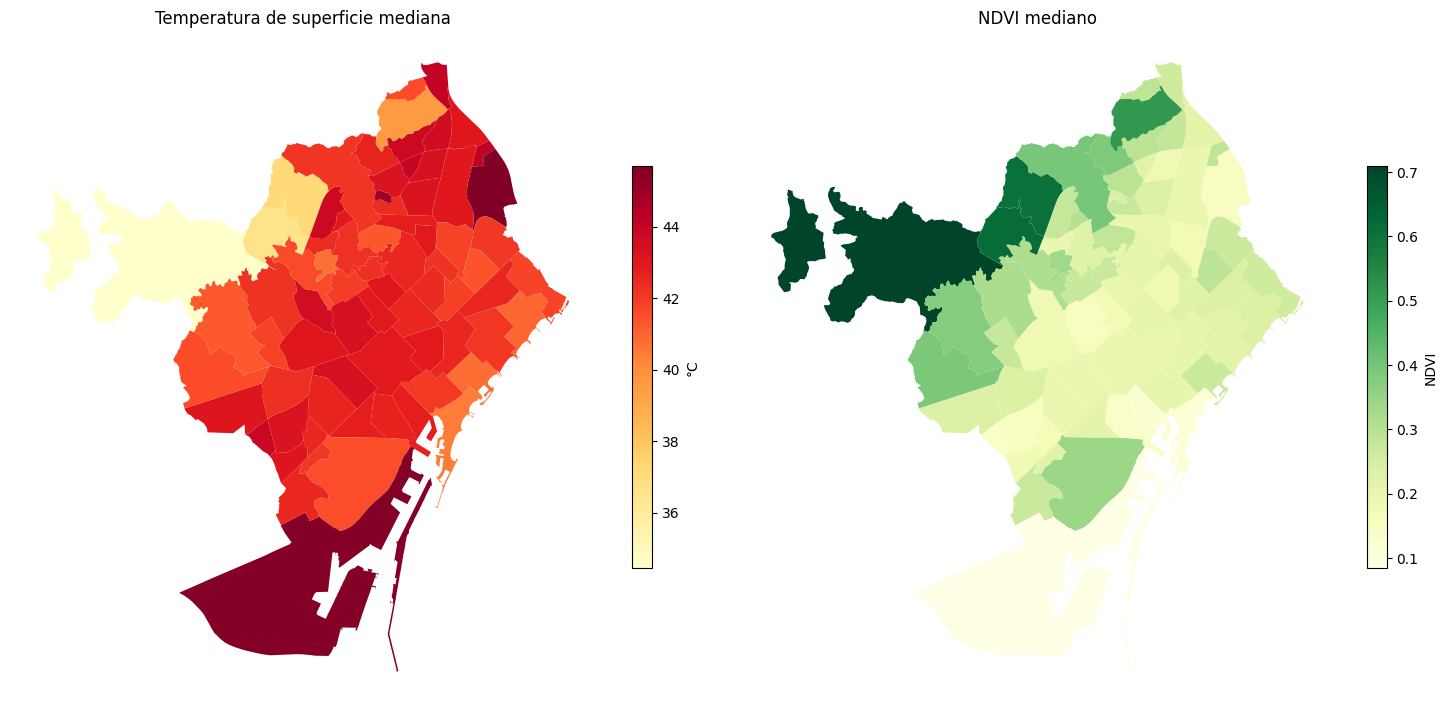

In [64]:
mapa = barrios.merge(calor[['codi_barri', 'temp_mediana', 'ndvi_mediana']], on='codi_barri')

fig, ejes = plt.subplots(1, 2, figsize=(15, 7))
mapa.plot(column='temp_mediana', cmap='YlOrRd', legend=True, ax=ejes[0], legend_kwds={'label': '°C', 'shrink': 0.6})
ejes[0].set_title('Temperatura de superficie mediana')
mapa.plot(column='ndvi_mediana', cmap='YlGn', legend=True, ax=ejes[1], legend_kwds={'label': 'NDVI', 'shrink': 0.6})
ejes[1].set_title('NDVI mediano')
for ax in ejes:
    ax.axis('off')
plt.tight_layout()
plt.show()

**Qué mirar:** A simple vista, El mapa verde (NDVI) actúa como un molde negativo del mapa térmico: donde hay más vegetación (verde oscuro), menos temperatura (amarillo claro). Es decir, las zonas más verdes coinciden con las más frescas.

### 4.5 Como leer los mapas

Los dos mapas muestran, barrio a barrio, el calor del suelo y la vegetación, para poder compararlos a simple vista.

Esto es lo que representa cada uno de los mapas:

#### 1. Mapa de Temperatura de Superficie Mediana (°C)
* **Qué mide:** La **temperatura del suelo** (*Land Surface Temperature* o LST), no la del aire. Está medida mediante sensores térmicos satelitales. Landsat pasa sobre Barcelona a media mañana (≈10:30 hora solar), no en el máximo térmico del día
* **Qué representa físicamente:** Cuánto se calientan los materiales y superficies de la ciudad (asfalto, hormigón, tejados, suelo desnudo).
* **Cómo leerlo:**
  * Las zonas **rojas oscuras** son las superficies que más se calientan (zonas industriales como el Bon Pastor o el puerto, y zonas densamente edificadas con poco árbol en calle). Pueden superar los 45 °C en el suelo.
  * Las zonas **claras o amarillas** son superficies más frescas, donde el suelo no acumula tanto calor.

#### 2. Mapa de NDVI Mediano (Índice de Vegetación de Diferencia Normalizada)
* **Qué mide:** El NDVI es un índice internacional (que va de -1 a 1) que mide la **densidad y la salud de la vegetación** a partir de la reflectancia de la luz solar (la clorofila de las plantas absorbe la luz roja y refleja fuertemente la infrarroja cercana).
* **Qué representa físicamente:** La cantidad de cobertura verde real (copas de árboles, parques, bosques, parterres) presente en cada barrio.
* **Cómo leerlo:**
  * El **verde oscuro** (valores cercanos a 0.6 o 0.7) representa bosques densos o parques muy grandes (como la sierra de Collserola en Vallvidrera).
  * El **verde muy claro o amarillento** (valores cercanos a 0.1 o inferiores) indica superficies sin vegetación: asfalto, edificios, suelo desnudo o agua.

####**Conclusión**
A simple vista, los barrios con más vegetación tienden a ser más frescos y los que tienen menos, más calientes. Es una **asociación, no una prueba de causa**: la vegetación reduce drásticamente la temperatura superficial del entorno urbano pero en la temperatura del suelo influyen también los materiales, la sombra de los edificios y la cercanía al mar.

## 5. Guardamos los datos limpios

In [65]:
calor[['codi_barri', 'temp_min', 'temp_max', 'temp_mediana', 'temp_media', 'temp_desv', 'temp_n_pixeles']].round(3).to_csv(
    PROCESSED + 'temperatura_por_barrio.csv', index=False, encoding='utf-8-sig')
calor[['codi_barri', 'ndvi_min', 'ndvi_max', 'ndvi_mediana', 'ndvi_media', 'ndvi_desv', 'ndvi_n_pixeles']].round(3).to_csv(
    PROCESSED + 'ndvi_por_barrio.csv', index=False, encoding='utf-8-sig')
print('Guardados: temperatura_por_barrio.csv y ndvi_por_barrio.csv (', len(calor), 'barrios )')

Guardados: temperatura_por_barrio.csv y ndvi_por_barrio.csv ( 73 barrios )
